## I. Preamble

In [1]:
import csv
import time
import threading
import os
from datetime import datetime
from collections import deque
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
import sys
sys.path.append(r"C:\TUC\03 Scripts\Laborinstrumente\src") #Folder of the library
import Controller336

In [3]:
channel_ColdPlate="a"
channel_FreeLength="b"
channel_RadShield="c"
channel_2ndStage="d"

## Configuration

In [4]:
controller=Controller336.device(channel_ColdPlate="a",
                                channel_FreeLength="b",
                                channel_RadShield="c",
                                channel_2ndStage="d") #Only the channel connected to the instrument


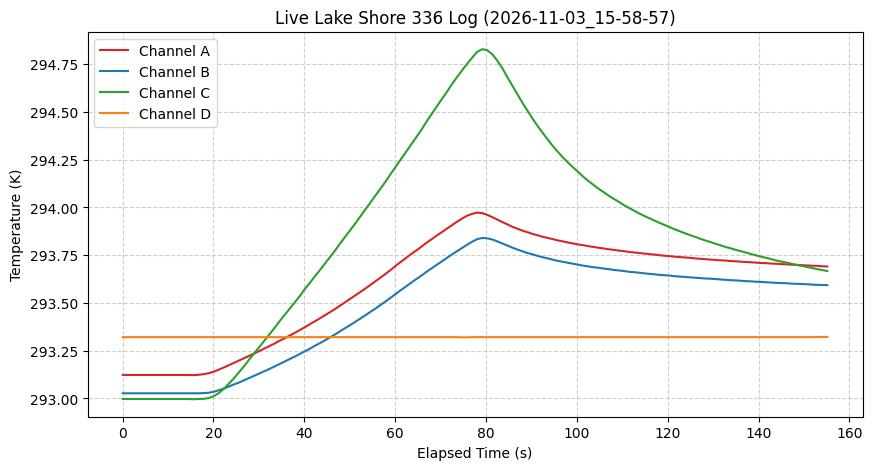

Background logging started. Saving to C:\TUC\03 Scripts\Laborinstrumente\ARS_data_logs\temperature_log_v2_2026-11-03_15-58-57.csv


In [5]:
# 1. CREATE A HARDWARE LOCK (Crucial for preventing communication crashes)
hw_lock = threading.Lock()

# 2. Setup Logging Variables
log_dir = r"C:\TUC\03 Scripts\Laborinstrumente\ARS_data_logs"
os.makedirs(log_dir, exist_ok=True)

start_time_str = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
CSV_FILENAME = os.path.join(log_dir, f"temperature_log_v2_{start_time_str}.csv")
INTERVAL_SEC = 1.0       # Read/Plot every 1 second
DISPLAY_POINTS = 600     # Keep last 600 points on screen (10 minutes)

# Data buffers
time_buffer = deque(maxlen=DISPLAY_POINTS)
ch1_buffer = deque(maxlen=DISPLAY_POINTS)
ch2_buffer = deque(maxlen=DISPLAY_POINTS)
ch3_buffer = deque(maxlen=DISPLAY_POINTS)
ch4_buffer = deque(maxlen=DISPLAY_POINTS)

# 3. Initialize Figure
fig, ax = plt.subplots(figsize=(10, 5))
plt.close(fig) # Prevent Jupyter from showing a duplicate static plot

# Create a display handle that the background thread can push updates to
display_handle = display(fig, display_id=True)

# Global flag to control the thread
keep_logging = True

def background_logger():
    # Initialize CSV
    with open(CSV_FILENAME, mode='a', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(["Timestamp", "Elapsed_Sec", "Temp_1", "Temp_2", "Temp_3", "Temp_4"])
        
    start_time = time.time()
    
    while keep_logging:
        # --- SAFELY READ HARDWARE ---
        try:
            with hw_lock:  # Lock the hardware bus!
                t1, t2, t3, t4 = controller.getTemperature()
        except Exception as e:
            print(f"Read error: {e}")
            time.sleep(INTERVAL_SEC)
            continue

        now = datetime.now()
        elapsed = time.time() - start_time

        # --- WRITE TO CSV IMMEDIATELY ---
        with open(CSV_FILENAME, mode="a", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([now.isoformat(), f"{elapsed:.2f}", t1, t2, t3, t4])
            f.flush()

        # --- UPDATE BUFFERS ---
        time_buffer.append(elapsed)
        ch1_buffer.append(t1)
        ch2_buffer.append(t2)
        ch3_buffer.append(t3)
        ch4_buffer.append(t4)

        # --- REDRAW GRAPH ---
        ax.clear()
        ax.plot(time_buffer, ch1_buffer, label="Channel A", color="tab:red", lw=1.5)
        ax.plot(time_buffer, ch2_buffer, label="Channel B", color="tab:blue", lw=1.5)
        ax.plot(time_buffer, ch3_buffer, label="Channel C", color="tab:green", lw=1.5)
        ax.plot(time_buffer, ch4_buffer, label="Channel D", color="tab:orange", lw=1.5)
        
        ax.set_title(f"Live Lake Shore 336 Log ({start_time_str})", fontsize=12)
        ax.set_xlabel("Elapsed Time (s)", fontsize=10)
        ax.set_ylabel("Temperature (K)", fontsize=10)
        ax.grid(True, linestyle="--", alpha=0.6)
        ax.legend(loc="upper left")

        # Push the updated figure to the specific output area
        display_handle.update(fig)
        
        time.sleep(INTERVAL_SEC)

# 4. Start the background thread
logger_thread = threading.Thread(target=background_logger)
logger_thread.start()
print(f"Background logging started. Saving to {CSV_FILENAME}")

In [6]:
with hw_lock:
    controller.startControlColdPlate(300)
    controller.startControlRadShield(300)
    print("Sending new temperature setpoint to controller...")

print("Command sent successfully! Watch the live graph above to see it adjust.")

Sending new temperature setpoint to controller...
Command sent successfully! Watch the live graph above to see it adjust.


In [ ]:
with hw_lock:
    controller.stopControl()

In [10]:
# Gracefully stop the background thread
keep_logging = False
logger_thread.join()

print("Logging stopped successfully.")

Logging stopped successfully.


In [12]:
## Command##

controller.getTemperature() #Read the temperature

(294.462, 294.368, 294.388, 294.578)

In [ ]:
controller.prepareHeaters()

In [ ]:
controller.startControlColdPlate(300)

In [ ]:
controller.startControlRadShield(300)

In [ ]:
controller.stopControl()